In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


### EDA

In [45]:
df = sns.load_dataset('diamonds', encoding='utf-8')
df.to_csv('diamonds.csv', index=False, encoding='utf-8')
df = pd.read_csv('diamonds.csv')    
 
df.head()
 

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  str    
 2   color    53940 non-null  str    
 3   clarity  53940 non-null  str    
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), str(3)
memory usage: 4.1 MB


In [47]:
df.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


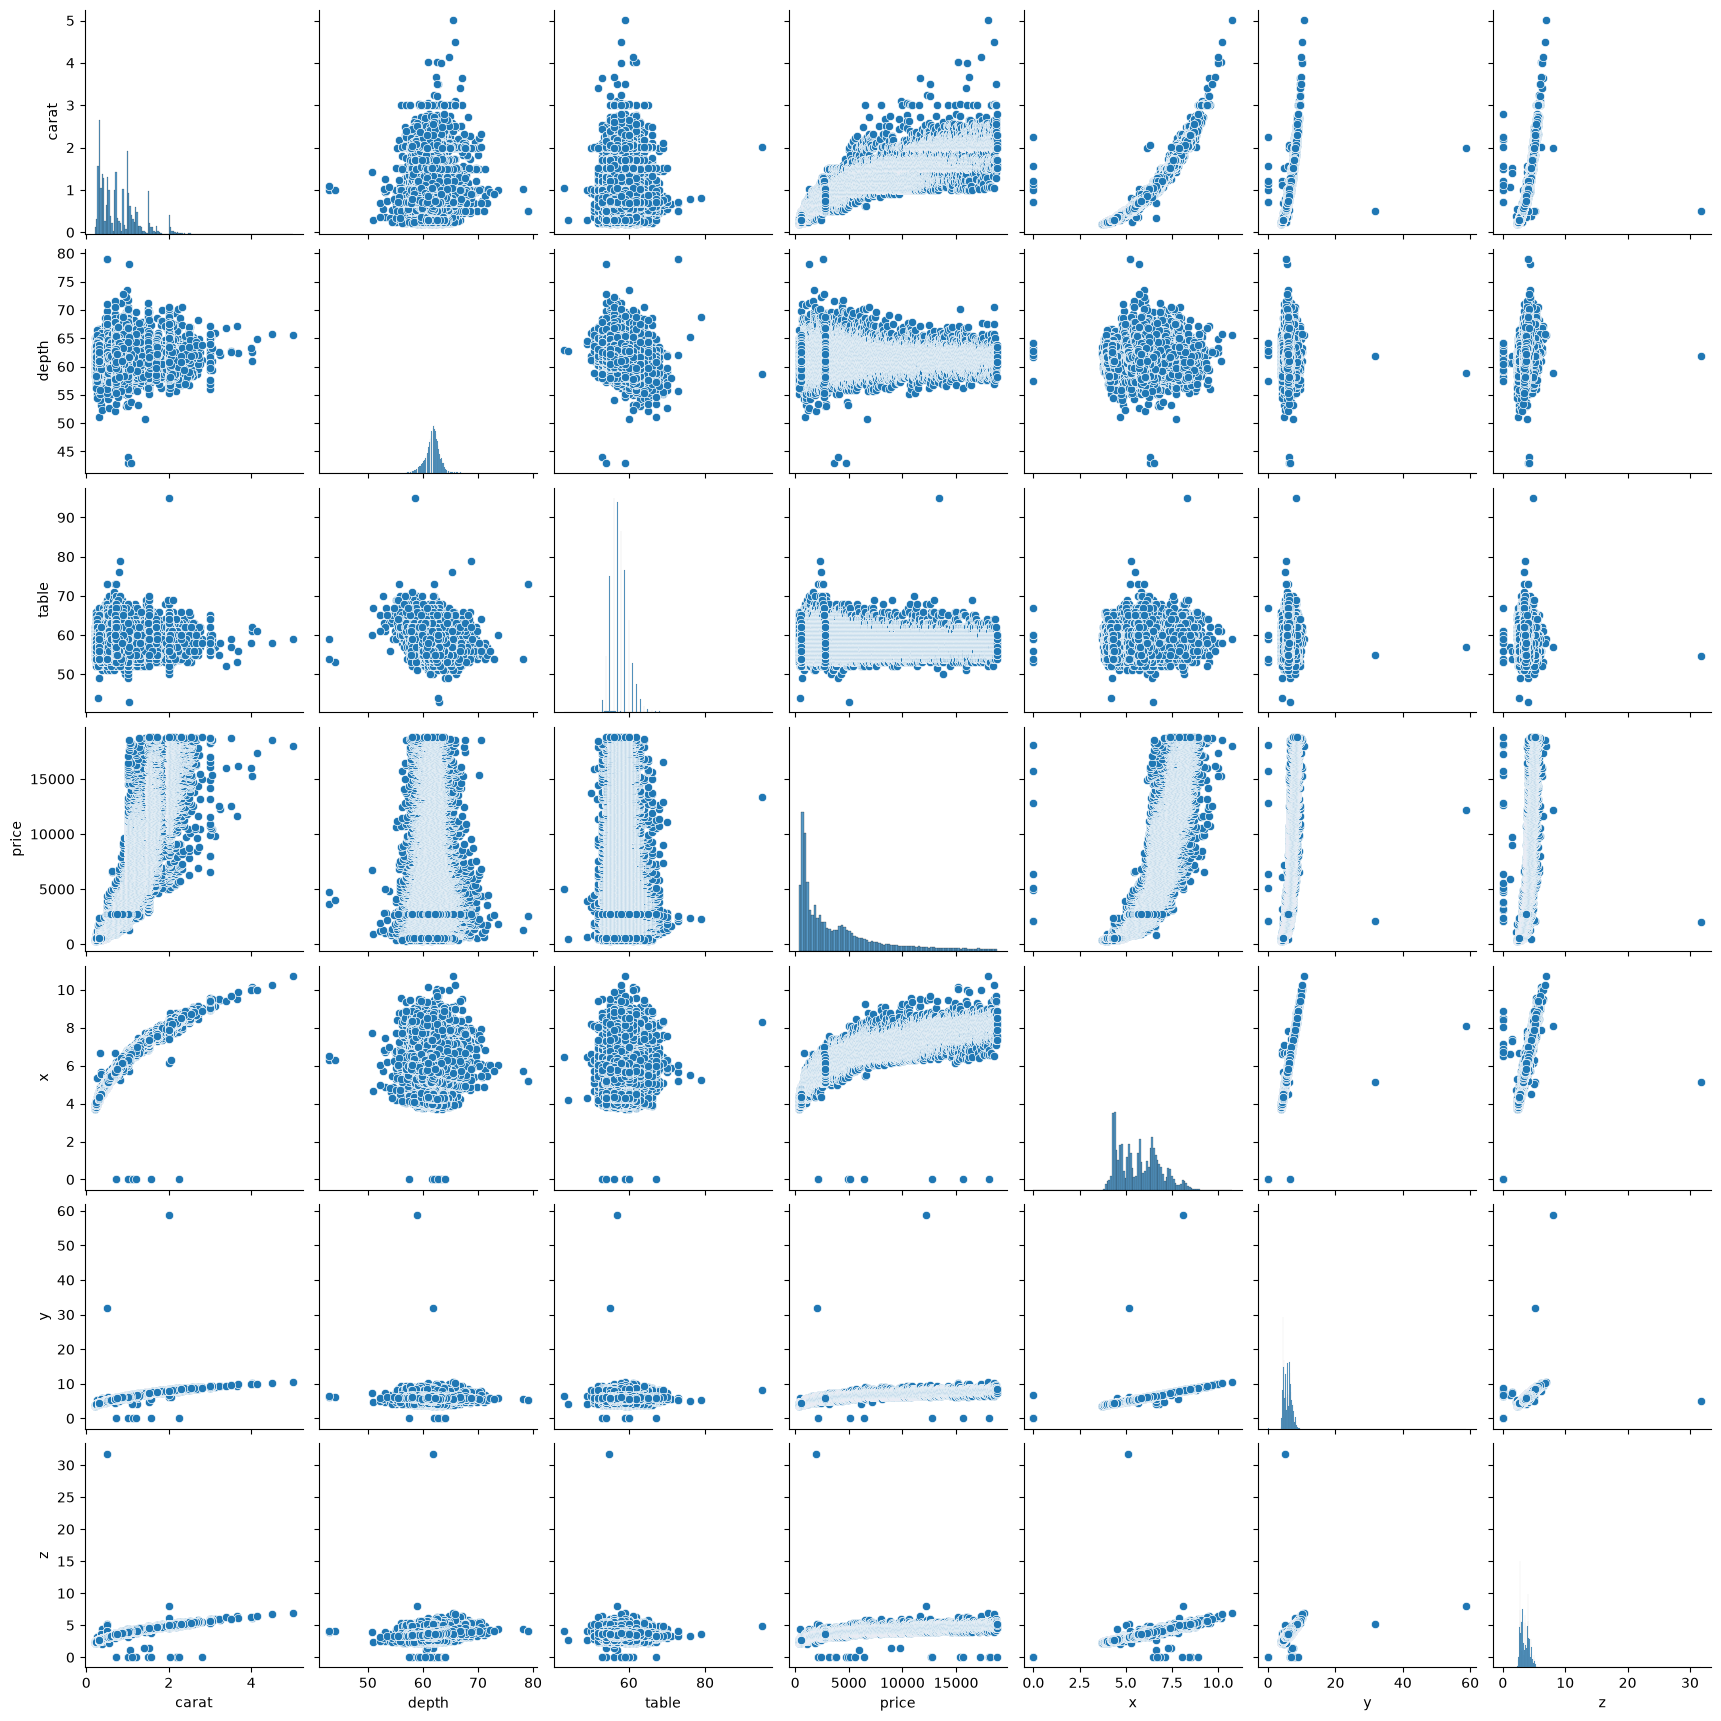

In [48]:
sns.pairplot(df);

### Data Cleaning

In [49]:
to_drop = df[(df['x']==0) | ( df['y']==0) | (df['z'] == 0)]
df.drop(to_drop.index, inplace=True)
to_drop = df[(df['y']>20)| (df['z']>20)]
df.drop(to_drop.index, inplace=True)

### Feature Engineering

In [50]:
feature_ext = ColumnTransformer([
    ('cut', OrdinalEncoder(
        categories=[['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']]), ['cut']),
    ('clarity', OrdinalEncoder(
        categories=[['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']]),
        ['clarity']),
    ('color', OneHotEncoder(sparse_output=False), ['color']),
    ('numeric', StandardScaler(), ['carat', 'depth', 'table', 'x', 'y', 'z'])
])

feature_ext.set_output(transform='pandas').fit_transform(df)

,cut__cut,clarity__clarity,color__color_D,color__color_E,color__color_F,color__color_G,color__color_H,color__color_I,color__color_J,numeric__carat,numeric__depth,numeric__table,numeric__x,numeric__y,numeric__z
0,4.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,-1.198226,-0.174240,-1.099770,-1.591584,-1.577872,-1.604088
1,3.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,-1.240440,-1.361138,1.585937,-1.645184,-1.703855,-1.777595
2,1.0,4.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,-1.198226,-3.385847,3.376409,-1.502249,-1.496883,-1.777595
3,3.0,3.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-1.071583,0.454118,0.243084,-1.368248,-1.352902,-1.314909
4,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,-1.029369,1.082475,0.243084,-1.243180,-1.244917,-1.141402
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53935,4.0,2.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.163975,-0.662963,-0.204534,0.016433,0.023911,-0.056981
53936,1.0,2.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.163975,0.942840,-1.099770,-0.037168,0.014912,0.102067
53937,2.0,2.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.206189,0.733388,1.138320,-0.063968,-0.048079,0.029772
53938,3.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.131526,-0.523328,0.243084,0.373770,0.347867,0.290033


In [51]:
df

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [52]:
X = df.drop('price', axis=1)
y = np.log(df['price'])

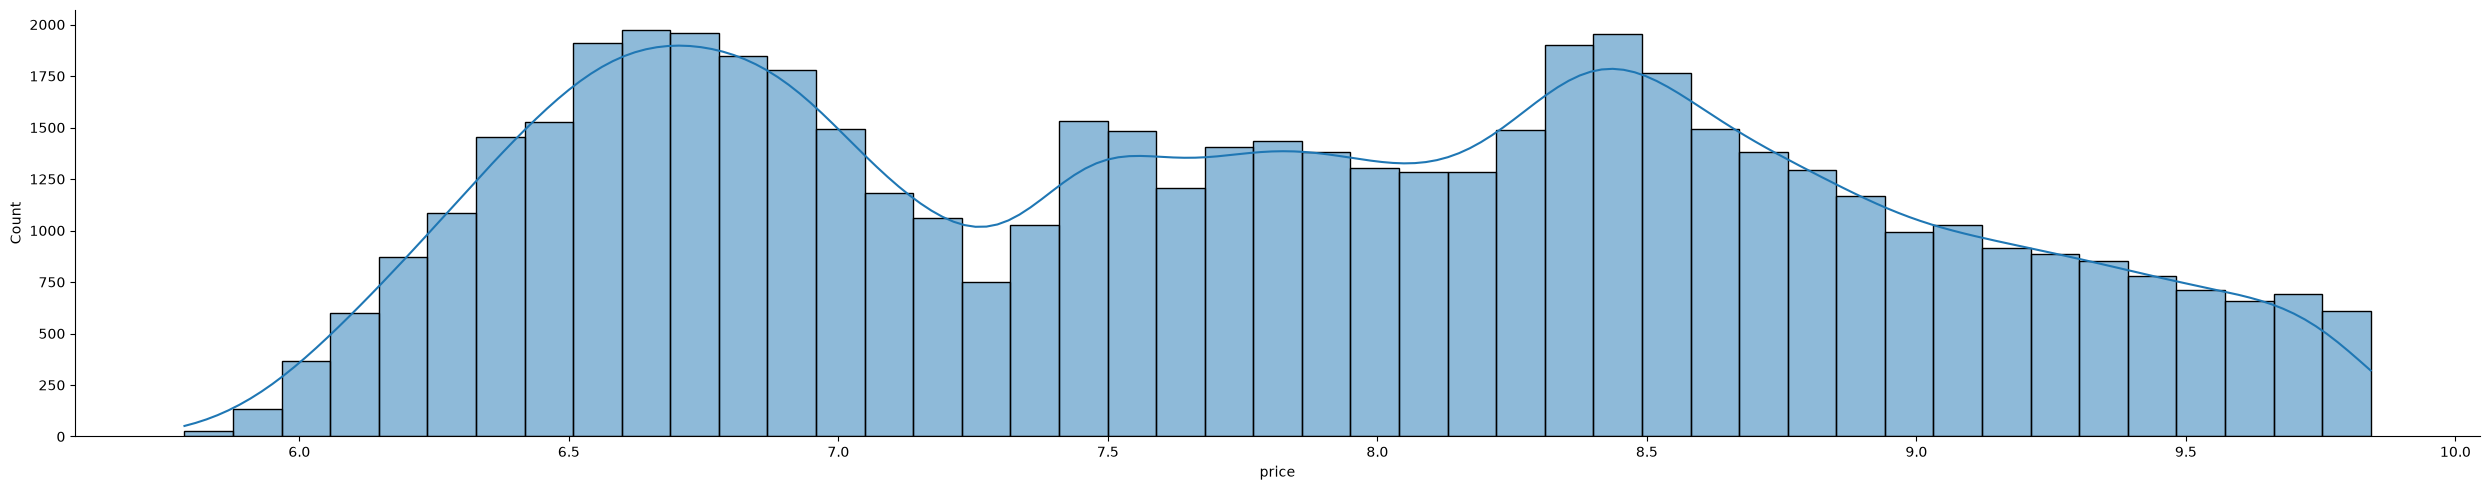

In [53]:
sns.displot(y, kde=True, aspect=5);

### Model Training

In [54]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(43133, 9) (10784, 9) (43133,) (10784,)


In [55]:
model = Pipeline([
    ('feature_ext', feature_ext),
    ('model', LinearRegression())
])

In [56]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_ext', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['carat','cut','color',...,'x','y','z']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cut', ...), ('clarity', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the o

In [57]:
y_test_exp = np.exp(y_test)
y_pred = model.predict(X_test)
y_pred_exp = np.exp(y_pred)
print(f"R2 score: {r2_score(y_test_exp, y_pred_exp)}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_exp, y_pred_exp))}")
print(f"MAE: {mean_absolute_error(y_test_exp, y_pred_exp)}")

R2 score: 0.9543480554481808
RMSE: 848.2423421067334
MAE: 439.35473038933674
